# Day 6 · 딥러닝과 학습 곡선 (AI 모델링)
AICE 2주 합격 플랜 · 영상 6편과 함께 풉니다. 공식 샘플 13·14번 형식입니다.
- 학습에 1분쯤 걸릴 수 있어요. 코랩에서 실행하세요.
- 딥러닝 결과는 컴퓨터마다 조금씩 다를 수 있어요. 숫자보다 흐름을 보세요.
- 모델을 만들 때 `input_dim` 관련 경고(UserWarning)가 떠도 에러가 아니에요. 그대로 진행하세요.

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 연습 데이터 내려받기
아래 셀을 먼저 실행하세요. 같은 폴더에 `aice_practice.csv` 가 생깁니다.

In [1]:
!wget -q -O aice_practice.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/aice_practice.csv
import os
print('준비 완료' if os.path.exists('aice_practice.csv') and os.path.getsize('aice_practice.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


### 준비: 3·5편에서 한 전처리와 분리, 스케일링 (실행만 하세요)
정답은 시험 샘플(Pass/Fail)처럼 글자(사망/생존)로 바꿔 둡니다.

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
df = pd.read_csv('aice_practice.csv')
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = pd.get_dummies(data=df, columns=['Sex', 'Embarked'])
X = df.drop('Survived', axis=1).astype(float)
y = df['Survived'].map({0: '사망', 1: '생존'})
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=7, stratify=y)
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_valid = ss.transform(X_valid)
y_train[:5].tolist()

['생존', '사망', '생존', '사망', '사망']

### 준비: 딥러닝 도구 불러오기 (샘플과 같은 셀)

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
tf.keras.utils.set_random_seed(1)

## 1. [직접 작성] 정답(y_train, y_valid)을 LabelEncoder 로 숫자로 바꾸세요
- 검증용은 학습용에서 만든 기준을 그대로 쓰세요.
- 학습용 정답의 앞 5개를 `답안1` 에 리스트로 저장하세요.

In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_valid = le.transform(y_valid)
print(le.classes_)
답안1 = y_train[:5].tolist()
답안1

['사망' '생존']


[1, 0, 1, 0, 0]

## 2. [직접 작성] 정답을 to_categorical 로 원 핫 형태로 바꾸고, y_train 의 모양(shape)을 `답안2` 에 저장하세요
- 1·2번을 다시 실행하려면 맨 위 준비 칸부터 다시 실행하세요(정답이 이미 바뀌어 있어요).

In [5]:
y_train = to_categorical(y_train)
y_valid = to_categorical(y_valid)
답안2 = y_train.shape
답안2

(420, 2)

## 3. [빈칸 채우기] 아래 구조로 모델을 만드세요 (샘플 13번 형식)
- Dense 128 (relu, input_dim=힌트 컬럼 수) → Dropout 0.3 → Dense 64 (relu) → Dense 32 (relu) → Dense 2 (sigmoid)
- 빈칸에 들어갈 말을 `답안3_1`, `답안3_2` 에 문자열로 저장하세요.

In [6]:
# 아래 코드의 빈칸을 채우고 실행하세요.
model = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid')
])
답안3_1 = 'Dropout'
답안3_2 = 'sigmoid'

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 4. [직접 작성] optimizer 는 adam, loss 는 binary_crossentropy, metrics 는 accuracy 로 컴파일하세요

In [7]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

## 5. [빈칸 채우기] val_loss 가 14번 나아지지 않으면 멈추도록 하고, 30바퀴·배치 128 로 학습하세요 (샘플 13번 형식)
- 학습 정보는 `history` 에 저장하세요.
- 빈칸에 들어갈 말을 `답안5` 에 문자열로 저장하고, 실제로 몇 바퀴 돌았는지 확인하세요.

In [8]:
# 아래 코드의 빈칸을 채우고 실행하세요.
estop = EarlyStopping(monitor='val_loss', patience=14)
history = model.fit(X_train, y_train, epochs=30, batch_size=128, validation_data=(X_valid, y_valid), callbacks=[estop])
답안5 = 'patience'
print('돈 바퀴 수:', len(history.history['loss']))

Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - accuracy: 0.5262 - loss: 0.6962 - val_accuracy: 0.5500 - val_loss: 0.6817
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6262 - loss: 0.6744 - val_accuracy: 0.6167 - val_loss: 0.6697
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7048 - loss: 0.6537 - val_accuracy: 0.6333 - val_loss: 0.6583
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7214 - loss: 0.6352 - val_accuracy: 0.6444 - val_loss: 0.6475
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7452 - loss: 0.6155 - val_accuracy: 0.6389 - val_loss: 0.6380
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7405 - loss: 0.5882 - val_accuracy: 0.6444 - val_loss: 0.6309
Epoch 7/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7405 - loss: 0.5665 - val_accuracy: 0.6444 - val_loss: 0.6281
Epoch 8/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7524 - loss: 0.5439 - val_accuracy: 0.6500 - val_loss: 0.6282


## 6. [직접 작성] 학습 Accuracy 와 검증 Accuracy 를 한 그래프에 그리세요 (샘플 14번 형식)
- 범례는 'acc', 'val_acc'
- 제목은 'Model Accuracy', x축은 'Epoch', y축은 'Accuracy'

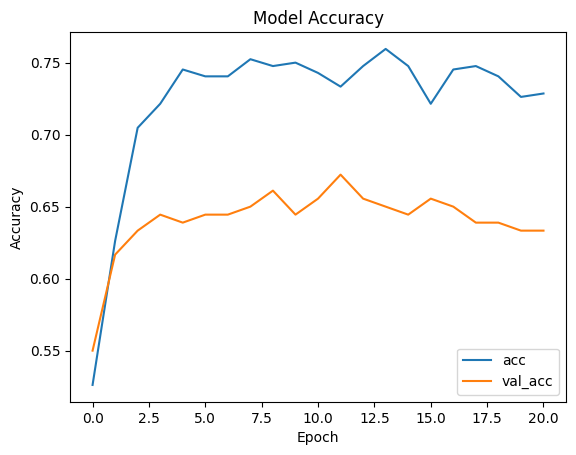

In [9]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['acc', 'val_acc'])
plt.show()

## 7. [생각해 보기] loss 와 val_loss 를 그려서, 검증 loss 가 가장 낮았던 바퀴 번호(1부터)를 `답안7` 에 저장하세요
그 뒤로 학습 loss 와 검증 loss 가 어떻게 달라지나요? 5편의 과적합과 연결해 보세요.

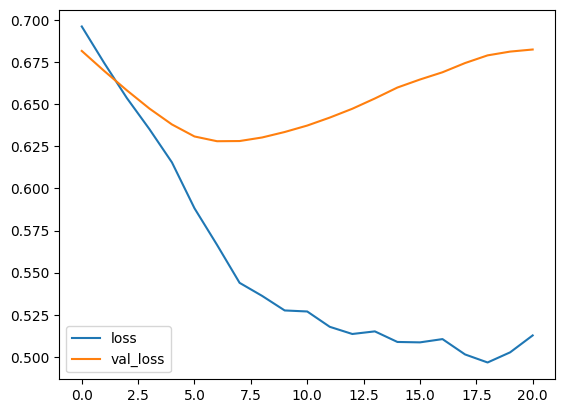

7

In [12]:
plt.plot(history.history['loss']) # 학습 loss
plt.plot(history.history['val_loss']) # 검증 loss
plt.legend(['loss', 'val_loss'])
plt.show()
답안7 = int(np.argmin(history.history['val_loss'])) +1 # np.argmin() ()안에서 가장 작은 값이 위치하는 인덱스 번호를 찾아라
답안7

## 8. [오류 정정] 아래 모델은 학습할 때 모양이 다르다는 에러가 납니다
- 정답은 to_categorical 로 두 칸이 됐습니다. 어디를 고쳐야 할까요?

In [13]:
# 아래의 코드를 정정하고 실행하세요.
# Before
# m = Sequential([Dense(16, activation='relu', input_dim=X_train.shape[1]), Dense(1, activation='sigmoid')])
# m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# m.fit(X_train, y_train, epochs=1)

# After
m = Sequential([Dense(16, activation='relu', input_dim=X_train.shape[1]), Dense(2, activation='sigmoid')])   # 정답 칸 수와 맞춘다
m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
m.fit(X_train, y_train, epochs=1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5000 - loss: 0.7499


---
### 오늘의 체크 (다 푼 뒤에 보세요. 정답이 들어 있어요)
- [ ] 정답: LabelEncoder(fit_transform / 검증은 transform) → to_categorical
- [ ] Sequential([Dense(…, activation='relu', input_dim=…), Dropout(0.3), …, Dense(2, activation='sigmoid')])
- [ ] compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
- [ ] EarlyStopping(monitor='val_loss', patience=…) → fit(…, validation_data=…, callbacks=[estop])
- [ ] history.history['accuracy'], ['val_accuracy'] → plot, title, xlabel, ylabel, legend
- [ ] 마지막 층 칸 수 = 정답 칸 수